In [2]:
import pandas as pd

df = pd.read_csv("../data/tox21_nr_ahr_clean.csv")

df.head()

,smiles,NR-AhR
0,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,1.0
1,CCN1C(=O)NC(c2ccccc2)C1=O,0.0
2,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,0.0
3,CC(C)(C)OOC(C)(C)CCC(C)(C)OOC(C)(C)C,0.0
4,O=S(=O)(Cl)c1ccccc1,0.0


In [3]:
df.shape
df.columns

Index(['smiles', 'NR-AhR'], dtype='str')

In [6]:
from rdkit import Chem

df['mol'] = df['smiles'].apply(Chem.MolFromSmiles)
df['mol'].isna().sum()

[23:55:57] WARNING: not removing hydrogen atom without neighbors


np.int64(0)

In [10]:
for feature_name, pattern in patterns.items():
    df[feature_name] = df["mol"].apply(
        lambda mol: int(mol.HasSubstructMatch(pattern))
    )

In [11]:
structural_features = [
    "has_indole",
    "has_benzothiazole",
    "has_halogenated_aromatic"
]

for feature in structural_features:
    count = df[feature].sum()
    positives = df.loc[df[feature] == 1, "NR-AhR"].sum()
    total = (df[feature] == 1).sum()
    
    positive_rate = positives / total if total > 0 else 0
    
    print(f"\n{feature}")
    print(f"Occurrences: {count}")
    print(f"NR-AhR positives: {positives}")
    print(f"Positive rate: {positive_rate:.3f}")


has_indole
Occurrences: 63
NR-AhR positives: 27.0
Positive rate: 0.429

has_benzothiazole
Occurrences: 30
NR-AhR positives: 26.0
Positive rate: 0.867

has_halogenated_aromatic
Occurrences: 928
NR-AhR positives: 185.0
Positive rate: 0.199


In [ ]:
print(df[structural_features].sum())

print("\nCo-occurrence matrix:")
print(df[structural_features].T.dot(df[structural_features]))

has_indole                   63
has_benzothiazole            30
has_halogenated_aromatic    928
dtype: int64

Co-occurrence matrix:
                          has_indole  has_benzothiazole  \
has_indole                        63                  0   
has_benzothiazole                  0                 30   
has_halogenated_aromatic           5                  6   

                          has_halogenated_aromatic  
has_indole                                       5  
has_benzothiazole                                6  
has_halogenated_aromatic                       928  


In [17]:
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors

df["MolWt"] = df["mol"].apply(Descriptors.MolWt)
df["MolLogP"] = df["mol"].apply(Descriptors.MolLogP)
df["TPSA"] = df["mol"].apply(Descriptors.TPSA)

df["NumHDonors"] = df["mol"].apply(Lipinski.NumHDonors)
df["NumHAcceptors"] = df["mol"].apply(Lipinski.NumHAcceptors)
df["NumRotatableBonds"] = df["mol"].apply(Lipinski.NumRotatableBonds)

df["RingCount"] = df["mol"].apply(Lipinski.RingCount)
df["NumAromaticRings"] = df["mol"].apply(Lipinski.NumAromaticRings)
df["HeavyAtomCount"] = df["mol"].apply(Lipinski.HeavyAtomCount)

df["FractionCSP3"] = df["mol"].apply( rdMolDescriptors.CalcFractionCSP3
)

feature_cols = [
    "MolWt",
    "MolLogP",
    "TPSA",
    "NumHDonors",
    "NumHAcceptors",
    "NumRotatableBonds",
    "RingCount",
    "NumAromaticRings",
    "HeavyAtomCount",
    "FractionCSP3"
]

print("Number of Model 2A descriptors:", len(feature_cols))
print(feature_cols)


Number of Model 2A descriptors: 10
['MolWt', 'MolLogP', 'TPSA', 'NumHDonors', 'NumHAcceptors', 'NumRotatableBonds', 'RingCount', 'NumAromaticRings', 'HeavyAtomCount', 'FractionCSP3']


In [18]:
feature_cols_2B = feature_cols + structural_features

print("Model 2B features:")
print(feature_cols_2B)

print("\nNumber of Model 2B features:", len(feature_cols_2B))

Model 2B features:
['MolWt', 'MolLogP', 'TPSA', 'NumHDonors', 'NumHAcceptors', 'NumRotatableBonds', 'RingCount', 'NumAromaticRings', 'HeavyAtomCount', 'FractionCSP3', 'has_indole', 'has_benzothiazole', 'has_halogenated_aromatic']

Number of Model 2B features: 13


In [26]:
X = df[feature_cols_2B].copy()
y = df["NR-AhR"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nX columns:")
print(X.columns.tolist())

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


X shape: (6534, 13)
y shape: (6534,)

X columns:
['MolWt', 'MolLogP', 'TPSA', 'NumHDonors', 'NumHAcceptors', 'NumRotatableBonds', 'RingCount', 'NumAromaticRings', 'HeavyAtomCount', 'FractionCSP3', 'has_indole', 'has_benzothiazole', 'has_halogenated_aromatic']


In [27]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [28]:
from xgboost import XGBClassifier
from sklearn.model_selection import cross_validate

xgb_2B = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=7,
    min_child_weight=1,
    subsample=0.8,
    colsample_bytree=1.0,
    scale_pos_weight=7.6,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

In [29]:
scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

cv_2B = cross_validate(
    xgb_2B,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

In [30]:
print("Model 2B CV ROC-AUC:",
      cv_2B["test_roc_auc"].mean())

print("Model 2B CV PR-AUC:",
      cv_2B["test_pr_auc"].mean())

print("\nROC-AUC folds:")
print(cv_2B["test_roc_auc"])

print("\nPR-AUC folds:")
print(cv_2B["test_pr_auc"])

Model 2B CV ROC-AUC: 0.8597851249204125
Model 2B CV PR-AUC: 0.5458555267502657

ROC-AUC folds:
[0.85102636 0.88494429 0.87028639 0.84929877 0.8433698 ]

PR-AUC folds:
[0.53446596 0.57609319 0.58265139 0.5137799  0.52228719]


In [31]:
xgb_2B.fit(X_train, y_train)


,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,1.0
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBR

In [32]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
y_prob_2B = xgb_2B.predict_proba(X_test)[:, 1]

y_pred_2B = xgb_2B.predict(X_test)


roc_auc_2B = roc_auc_score(y_test, y_prob_2B)
pr_auc_2B = average_precision_score(y_test, y_prob_2B)
precision_2B = precision_score(y_test, y_pred_2B)
recall_2B = recall_score(y_test, y_pred_2B)
f1_2B = f1_score(y_test, y_pred_2B)

print("Model 2B Test ROC-AUC:", roc_auc_2B)
print("Model 2B Test PR-AUC:", pr_auc_2B)
print("Model 2B Test Precision:", precision_2B)
print("Model 2B Test Recall:", recall_2B)
print("Model 2B Test F1:", f1_2B)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_2B))

Model 2B Test ROC-AUC: 0.8758885850991115
Model 2B Test PR-AUC: 0.5307902888804539
Model 2B Test Precision: 0.4372093023255814
Model 2B Test Recall: 0.618421052631579
Model 2B Test F1: 0.5122615803814714

Confusion Matrix:
[[1034  121]
 [  58   94]]


In [33]:
import shap

explainer_2B = shap.TreeExplainer(xgb_2B)
shap_values_2B = explainer_2B(X_test)

In [34]:
print(shap_values_2B.shape)

(1307, 13)


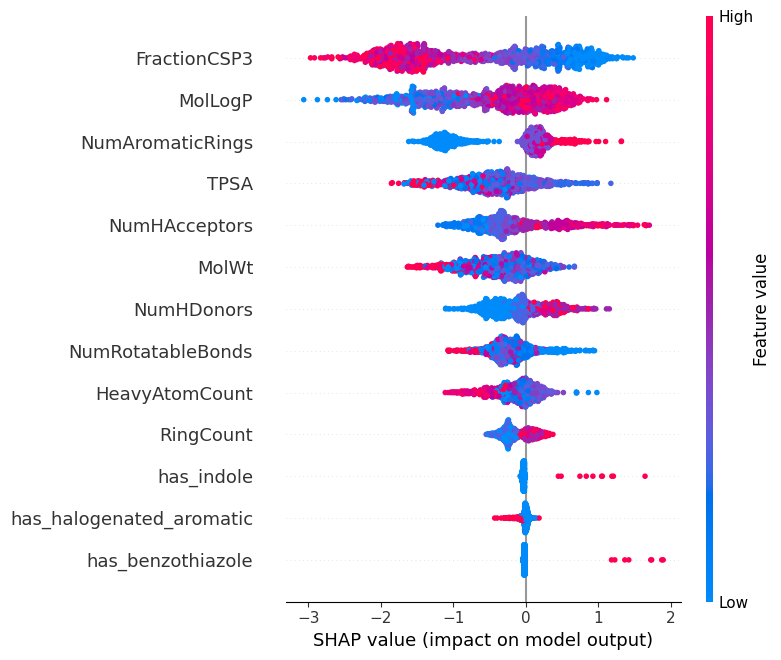

In [35]:
shap.summary_plot(shap_values_2B, X_test)

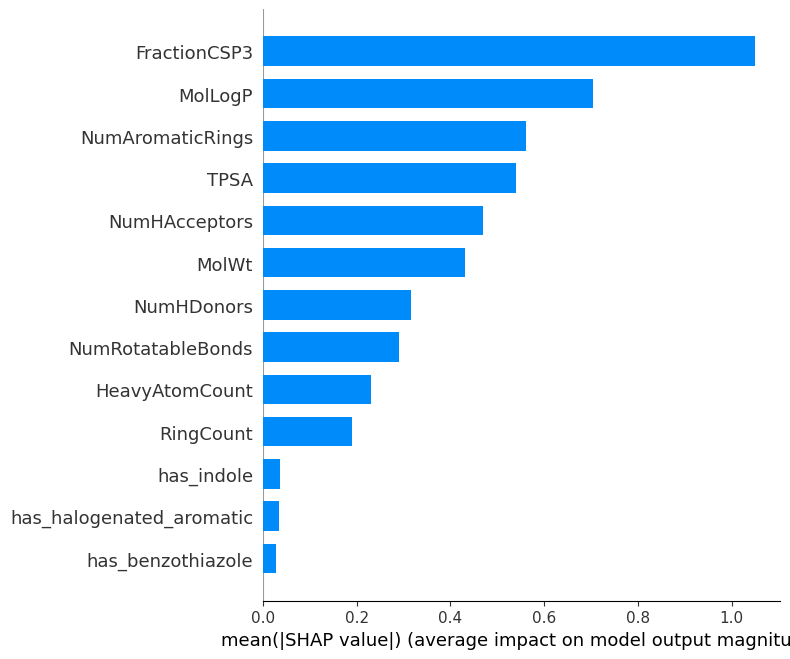

In [36]:
shap.summary_plot(shap_values_2B, X_test, plot_type="bar")

In [37]:
structural_features = [
    "has_indole",
    "has_benzothiazole",
    "has_halogenated_aromatic"
]

for feature in structural_features:
    feature_index = X_test.columns.get_loc(feature)
    values = X_test[feature].values
    feature_shap = shap_values_2B.values[:, feature_index]

    print(feature)
    print("Mean SHAP when absent:", feature_shap[values == 0].mean())
    print("Mean SHAP when present:", feature_shap[values == 1].mean())
    print()

has_indole
Mean SHAP when absent: -0.029870706
Mean SHAP when present: 0.95821494

has_benzothiazole
Mean SHAP when absent: -0.019399345
Mean SHAP when present: 1.5526791

has_halogenated_aromatic
Mean SHAP when absent: -0.0010724007
Mean SHAP when present: -0.10096467

